# Filling gaps in smart-meter load profiles

Smart meters record electricity use every 15 minutes. When a meter or its
communication link fails, the load profile has gaps in it. This notebook trains
a model that fills gaps of up to 24 hours and checks whether it does better than
the linear interpolation normally used. The filled values are only for drawing
a customer's load-profile graph; they are not used for billing.

The real meter data belongs to the utility's customers and cannot be published.
`synthetic_load_profile.csv` holds 200 synthetic meters over six months (January
to June 2026) at 15-minute resolution. They were generated to match statistics of
the real data, measured across all its meters: how large meters are, how much
their load moves from one reading to the next, their daily and weekly patterns,
seasonal and holiday changes, zero readings, and how long and how often gaps
occur. No real meter's readings are in the file.

Running every cell writes `smart_meter_data_imputation_model.joblib`, the trained model.

| Section | |
|---|---|
| 1 | Setup |
| 2 | The data |
| 3 | Preparing the data |
| 4 | Train / test split |
| 5 | Simulated gaps |
| 6 | Feature engineering |
| 7 | Baselines |
| 8 | The model |
| 9 | Evaluation |
| 10 | Ablation |
| 11 | Using the model on real meter gaps |
| 12 | Saving the model |

## 1. Setup

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 160)

INTERVALS_PER_DAY = 96                         # 15-minute readings per day
INTERVALS_PER_WEEK = 7 * INTERVALS_PER_DAY
GAP_LENGTHS = (1, 4, 12, 20, 32, 48, 64, 96)   # simulated gap lengths: 15 min to 24 h
TEST_FRACTION = 0.2                            # last 20% of the timeline is the test period
MASK_FRACTION = 0.03                           # share of readings hidden in one scenario
MIN_SEPARATION = 8                             # readings kept between two simulated gaps
N_SCENARIOS_TRAIN, N_SCENARIOS_TEST = 12, 6
MAX_FILL = 96                                  # longest gap that is filled (24 h)
DAYS_PER_MONTH = 365.25 / 12                   # average month, to state a meter's size in kWh per month
SEED = 42

## 2. The data

One row per 15-minute interval and one column per meter, in kW. A timestamp marks
the end of its interval (`00:15` covers 00:00 to 00:15). An empty cell means the
meter did not report, while `0` is a real reading of zero use.

In [2]:
df = pd.read_csv("synthetic_load_profile.csv", index_col="timestamp", parse_dates=True)
print(f"{df.shape[1]} meters x {df.shape[0]:,} intervals, "
      f"{df.index[0]} to {df.index[-1]}")
missing = df.isna().to_numpy()
print(f"missing readings (empty cells, zeros not counted): {missing.sum():,} of {missing.size:,} "
      f"intervals ({missing.mean():.1%})")
df.iloc[:5, :6]

200 meters x 17,376 intervals, 2026-01-01 00:15:00 to 2026-07-01 00:00:00
missing readings (empty cells, zeros not counted): 343,986 of 3,475,200 intervals (9.9%)


,M001,M002,M003,M004,M005,M006
timestamp,,,,,,
2026-01-01 00:15:00,0.384,3.700,NaN,0.0,NaN,0.076
2026-01-01 00:30:00,0.424,3.508,NaN,0.0,NaN,0.076
2026-01-01 00:45:00,0.424,3.348,NaN,0.0,NaN,0.064
2026-01-01 01:00:00,0.404,3.360,NaN,0.0,NaN,0.080
2026-01-01 01:15:00,0.392,2.124,NaN,0.0,NaN,0.100


In [3]:
# A reading is the average power (kW) over 15 minutes, so a day's energy is mean kW x 24 h (kWh)
summary = pd.DataFrame({
    "mean kW (15-min readings)": df.mean(),
    "kWh per day": df.mean() * 24,
    "kWh per month": df.mean() * 24 * DAYS_PER_MONTH,
    "max kW": df.max(),
    "zero readings %": (df == 0).mean() * 100,
    "missing %": df.isna().mean() * 100,
})

spread = summary.quantile([0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0])
spread.index = ["minimum", "5th percentile", "25th percentile", "median",
                "75th percentile", "95th percentile", "maximum"]
spread.loc["mean"] = summary.mean()
spread.round(2)

,mean kW (15-min readings),kWh per day,kWh per month,max kW,zero readings %,missing %
minimum,0.00,0.00,0.01,0.00,0.00,0.00
5th percentile,0.00,0.02,0.58,0.10,0.00,0.00
25th percentile,0.20,4.74,144.40,2.74,0.02,0.03
median,0.64,15.44,469.84,7.25,0.07,0.80
75th percentile,1.31,31.50,958.68,17.30,8.12,9.46
95th percentile,5.54,132.93,4046.15,62.03,89.58,42.82
maximum,18.36,440.54,13409.07,495.58,99.72,73.22
mean,1.47,35.26,1073.16,18.87,13.62,9.90


Each row of the table describes the 200 meters. The median meter uses about
15 kWh a day, or 470 kWh a month. Three quarters use less than about 960 kWh a
month, a few are much larger, and about one in eight is almost empty (a vacant
unit). Because sizes vary this much, errors are later
divided by each meter's mean load.

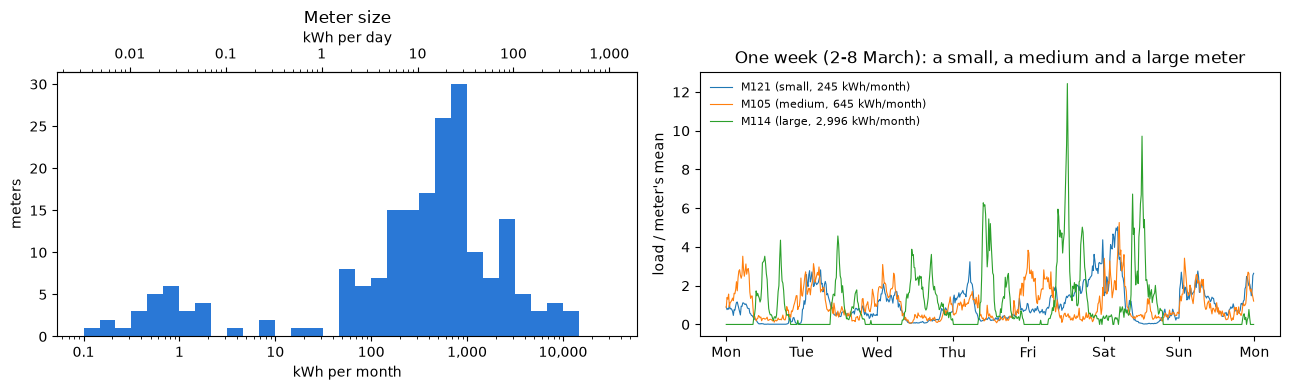

In [4]:
kwh_month = df.mean() * 24 * DAYS_PER_MONTH
plain = plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,g}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(kwh_month.clip(lower=0.1), bins=np.logspace(-1, 4.5, 34), color="#2a78d6")
axes[0].set_xscale("log"); axes[0].xaxis.set_major_formatter(plain)
axes[0].set_xlabel("kWh per month"); axes[0].set_ylabel("meters")
per_day = axes[0].secondary_xaxis("top", functions=(lambda m: m / DAYS_PER_MONTH,
                                                    lambda d: d * DAYS_PER_MONTH))
per_day.xaxis.set_major_formatter(plain); per_day.set_xlabel("kWh per day")
axes[0].set_title("Meter size")

# three meters with every reading that week: a small, a medium and a large one;
# divided by its own mean, each meter's daily shape can be compared whatever its size
week = df.loc["2026-03-02":"2026-03-08"]
complete = week.columns[week.notna().all() & (df.mean() > 0.2)]
ranked = kwh_month[complete].sort_values()
picks = ranked.index[[int(len(ranked) * 0.1), len(ranked) // 2, int(len(ranked) * 0.9)]]
for meter, size in zip(picks, ["small", "medium", "large"]):
    axes[1].plot(week.index, week[meter] / df[meter].mean(), lw=0.8,
                 label=f"{meter} ({size}, {kwh_month[meter]:,.0f} kWh/month)")
axes[1].set_ylabel("load / meter's mean")
axes[1].set_title("One week (2-8 March): a small, a medium and a large meter")
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a"))
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Load through the day

Each meter's load is divided by its own mean, and the lines are the median
across meters. Meters averaging under 0.2 kW are left out because dividing by a
mean close to zero blows up their readings.

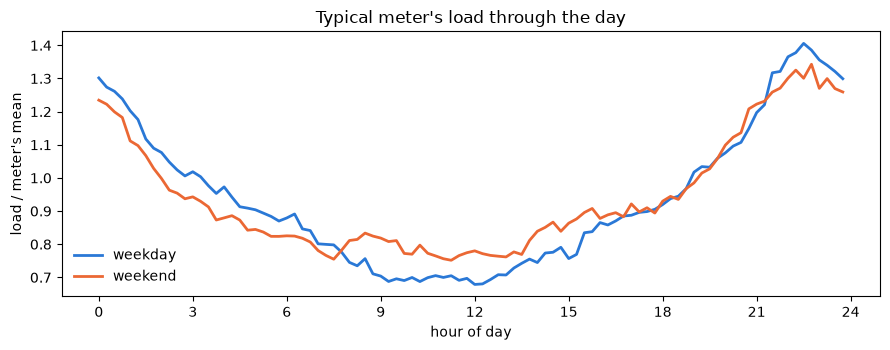

In [5]:
relative = (df / df.mean()).loc[:, df.mean() > 0.2]
start = df.index - pd.Timedelta("15min")          # the interval each reading covers starts here
hour = start.hour + start.minute / 60
weekend = start.dayofweek >= 5
by_hour = pd.DataFrame({
    "weekday": relative[~weekend].groupby(hour[~weekend]).mean().median(axis=1),
    "weekend": relative[weekend].groupby(hour[weekend]).mean().median(axis=1),
})

fig, ax = plt.subplots(figsize=(9, 3.6))
by_hour.plot(ax=ax, color=["#2a78d6", "#eb6834"], lw=2)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day"); ax.set_ylabel("load / meter's mean")
ax.set_title("Typical meter's load through the day")
ax.legend(frameon=False)
plt.tight_layout()

On weekdays load is lowest around noon, about 0.7 of the meter's mean, when many
people are out, and highest around 22:30, about 1.4 times the mean, when air
conditioners run at night. At weekends the midday dip is shallower. The load can
double within a few hours, which linear interpolation across a long gap cannot
follow. The model gets the time of day through `tod_sin` and `tod_cos`.

The same shape as a heatmap, by day of week.

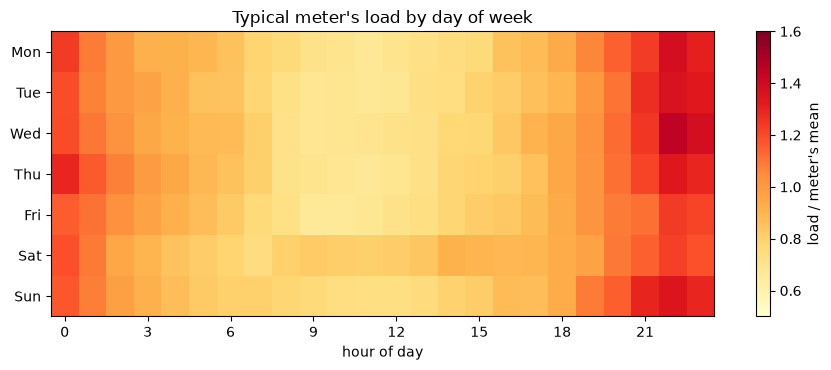

In [6]:
by_weekday = relative.groupby([start.dayofweek, start.hour]).mean().median(axis=1).unstack()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(9, 3.8))
image = ax.imshow(by_weekday.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0.5, vmax=1.6)
ax.set_yticks(range(7)); ax.set_yticklabels(by_weekday.index)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of day")
ax.set_title("Typical meter's load by day of week")
fig.colorbar(image, ax=ax, label="load / meter's mean")
plt.tight_layout()

Every day the load peaks around 22:00. On Saturday the daytime load, from 8:00
to 17:00, is higher than on weekdays, and on Friday and Saturday nights the peak
is lower than on other nights. The day of the week changes the shape of the day,
which is why I chose to give the model the meter's average load for each weekday
and time of day.

## 3. Preparing the data

### Timestamps

I sort the rows by time, keep the first row when a timestamp appears twice,
drop timestamps that are off the 15-minute grid, and add an empty row for every
missing interval, so a missing reading shows up as an empty cell.

In [7]:
changes = {}

grid = pd.date_range(df.index.min().ceil("15min"), df.index.max().floor("15min"),
                     freq="15min", name="timestamp")
print("timestamps in order:", df.index.is_monotonic_increasing)
print("duplicate timestamps:", df.index.duplicated().sum())
print("intervals missing from the 15-minute grid:", len(grid.difference(df.index)))
print("timestamps off the 15-minute grid:", len(df.index.difference(grid)))

changes["duplicate timestamps removed"] = int(df.index.duplicated().sum())
changes["missing intervals added as empty rows"] = len(grid.difference(df.index))
changes["timestamps off the grid dropped"] = len(df.index.difference(grid))
df = df[~df.index.duplicated()].sort_index().reindex(grid)

timestamps in order: True
duplicate timestamps: 0
intervals missing from the 15-minute grid: 0
timestamps off the 15-minute grid: 0


### Reading values

Every column should hold numbers. A reading is the average power over 15
minutes, so it cannot be negative, and I turn negative values into `NaN`.

In [8]:
print("column types:", df.dtypes.astype(str).value_counts().to_dict())
negative = int((df < 0).sum().sum())
print("negative readings:", negative)

changes["negative readings set to missing"] = negative
df = df.mask(df < 0)

column types: {'float64': 200}
negative readings: 0


### Meters

True zeros stay. `0 kW` means nothing was used, and treating it as missing
would invent consumption that never happened. A meter that never reported, or
that reads zero throughout, is dropped, since that points to a fault in the
meter or its wiring rather than a customer.

In [9]:
readings = df.notna().sum()
no_readings = list(readings[readings == 0].index)
all_zero = [m for m in df.columns if readings[m] > 0 and df[m].max() == 0]
print("meters with no readings:", no_readings or "none")
print("meters reading zero throughout:", all_zero or "none")

changes["meters dropped"] = len(no_readings) + len(all_zero)
df = df.drop(columns=no_readings + all_zero)

index = df.index
values = df.to_numpy(dtype=float)
meters = list(df.columns)
pd.Series(changes, name="count").to_frame()

meters with no readings: none
meters reading zero throughout: none


,count
duplicate timestamps removed,0
missing intervals added as empty rows,0
timestamps off the grid dropped,0
negative readings set to missing,0
meters dropped,0


### Gaps

I count the real gaps in the data by length.

In [10]:
def gap_runs(column):
    # (start, length) of every run of missing readings that has a reading on both sides
    missing = np.isnan(column)
    edges = np.flatnonzero(np.diff(np.concatenate(([0], missing.astype(int), [0]))))
    runs = [(a, b - a) for a, b in zip(edges[::2], edges[1::2])]
    return [(a, n) for a, n in runs if a > 0 and a + n < len(column)]

lengths = np.array([n for j in range(values.shape[1]) for _, n in gap_runs(values[:, j])])
buckets = pd.cut(lengths, [0, 1, 4, 20, 96, 10**6],
                 labels=["15 min", "<= 1 h", "<= 5 h", "<= 24 h", "> 24 h"])
real_gaps = pd.DataFrame({"gaps": pd.Series(buckets).value_counts().sort_index()})
real_gaps["missing readings"] = pd.Series(lengths).groupby(buckets, observed=False).sum().values
real_gaps

,gaps,missing readings
15 min,7,7
<= 1 h,301,709
<= 5 h,171,1383
<= 24 h,85,4684
> 24 h,64,38050


Most gaps are short, but the few gaps longer than a day hold most of the missing
readings. Those are left for review instead of being filled.

## 4. Train / test split

The first 80% of the timeline trains the model and the last 20% tests it. The
split is by time because a random split would let readings from the future leak
into training. Two things are computed from the training period only:

- `mean_load`, each meter's mean load, which divides every load feature so one
  model works for meters of any size;
- `weekday_time_average_load`, each meter's average load for every weekday and
  time of day.

In [11]:
split = int(len(index) * (1 - TEST_FRACTION))
print(f"train: {index[0]} to {index[split - 1]}   test: {index[split]} to {index[-1]}")

def compute_mean_load(values, upto=None):
    with np.errstate(invalid="ignore"):
        mean = np.nanmean(values[:upto], axis=0)
    return np.where(np.isfinite(mean) & (mean > 0), mean, 1.0)

def compute_weekday_time_average_load(values, index, upto=None):
    slot = index.dayofweek.to_numpy() * 96 + index.hour.to_numpy() * 4 + index.minute.to_numpy() // 15
    average = np.full((values.shape[1], INTERVALS_PER_WEEK), np.nan)
    for j in range(values.shape[1]):
        column, s = values[:upto, j], slot[:upto]
        seen = ~np.isnan(column)
        if seen.any():
            total = np.bincount(s[seen], weights=column[seen], minlength=INTERVALS_PER_WEEK)
            count = np.bincount(s[seen], minlength=INTERVALS_PER_WEEK)
            with np.errstate(invalid="ignore", divide="ignore"):
                average[j] = np.where(count > 0, total / np.maximum(count, 1), np.nan)
    return average

mean_load = compute_mean_load(values, upto=split)
weekday_time_average_load = compute_weekday_time_average_load(values, index, upto=split)

train: 2026-01-01 00:15:00 to 2026-05-25 19:00:00   test: 2026-05-25 19:15:00 to 2026-07-01 00:00:00


In [12]:
# Fixed-date Thai public holidays
HOLIDAYS = [(1, 1), (4, 6), (4, 13), (4, 14), (4, 15), (5, 1), (5, 4), (6, 3), (7, 28),
            (8, 12), (10, 13), (10, 23), (12, 5), (12, 10), (12, 31)]

def holiday_flags(index):
    flags = np.zeros(len(index))
    for month, day in HOLIDAYS:
        flags[(index.month == month) & (index.day == day)] = 1.0
    return flags

holiday = holiday_flags(index)

## 5. Simulated gaps

A real gap has no true values to compare a fill with. So I hide readings that do
exist, in blocks of 15 minutes to 24 hours, let each method fill them, and compare
the fills with what was hidden. The training rows are built the same way, so the
model learns from the situation it will meet in use.

Each scenario hides about 3% of a meter's readings and keeps at least 8 real
readings between two hidden blocks. Shorter lengths are drawn more often
(probability proportional to 1/length) so that every length gets enough rows.

The gaps are simulated after the split, separately for each period: training gaps
only in the training period and test gaps only in the test period. A gap can then
never straddle the boundary, and no training row is built from test-period
readings.

In [13]:
def simulate_mask(observed, rng, window):
    n_times, n_meters = observed.shape
    start, stop = window
    mask = np.zeros_like(observed, dtype=bool)
    lengths = np.asarray(GAP_LENGTHS)
    weights = (1.0 / lengths) / (1.0 / lengths).sum()
    for j in range(n_meters):
        eligible = observed[start:stop, j]
        budget = int(eligible.sum() * MASK_FRACTION)
        if budget < lengths.min():
            continue
        available = eligible.copy()
        masked, attempts = 0, 0
        max_attempts = 40 * (budget // max(1, int(lengths.mean())) + 1)
        while masked < budget and attempts < max_attempts:
            attempts += 1
            length = int(rng.choice(lengths, p=weights))
            latest = len(available) - length - MIN_SEPARATION
            if latest <= MIN_SEPARATION:
                continue
            offset = int(rng.integers(MIN_SEPARATION, latest))
            if not available[offset - MIN_SEPARATION: offset + length + MIN_SEPARATION].all():
                continue
            mask[start + offset: start + offset + length, j] = True
            available[offset - MIN_SEPARATION: offset + length + MIN_SEPARATION] = False
            masked += length
    return mask

example = simulate_mask(~np.isnan(values), np.random.default_rng(SEED), (0, split - 96))
print(f"one training scenario hides {example.sum():,} readings")

one training scenario hides 75,748 readings


## 6. Feature engineering

| Feature | Meaning |
|---|---|
| `reading_previous` | the last reading before the gap |
| `reading_next` | the first reading after the gap |
| `reading_linear_interpolation` | the linear interpolation value between `reading_previous` and `reading_next` at this position |
| `reading_previous_day` | the reading at the same time one day earlier (empty if that is missing too) |
| `reading_next_day` | the reading at the same time one day later |
| `reading_previous_week` | the reading at the same time one week earlier |
| `weekday_time_average_load` | the meter's average load for this weekday and time of day, from the training period |
| `intervals_since_previous` | 15-minute intervals since `reading_previous` |
| `intervals_until_next` | 15-minute intervals until `reading_next` |
| `gap_len` | length of the gap, in readings |
| `tod_sin` | sine of the time of day (one cycle per day) |
| `tod_cos` | cosine of the time of day; with `tod_sin` it puts 23:45 next to 00:00 |
| `is_holiday` | 1 on a fixed-date Thai public holiday, otherwise 0 |

Every `reading_` feature and `weekday_time_average_load` are divided by the meter's
mean load.

In [14]:
FEATURES = ["reading_previous", "reading_next", "reading_linear_interpolation",
            "reading_previous_day", "reading_next_day", "reading_previous_week",
            "weekday_time_average_load", "intervals_since_previous", "intervals_until_next",
            "gap_len", "tod_sin", "tod_cos", "is_holiday"]

def shift(column, periods):
    out = np.full_like(column, np.nan)
    if periods > 0:
        out[periods:] = column[:-periods]
    else:
        out[:periods] = column[-periods:]
    return out

def neighbours(column):
    # value of, and distance to, the nearest reading before and after every position
    n = len(column)
    seen = ~np.isnan(column)
    pos = np.arange(n)
    prev_pos = np.maximum.accumulate(np.where(seen, pos, -1))
    next_pos = np.minimum.accumulate(np.where(seen, pos, n)[::-1])[::-1]
    has_prev, has_next = prev_pos >= 0, next_pos < n
    prev_value = np.where(has_prev, column[np.clip(prev_pos, 0, n - 1)], np.nan)
    next_value = np.where(has_next, column[np.clip(next_pos, 0, n - 1)], np.nan)
    since = np.where(has_prev, pos - prev_pos, np.nan).astype(float)
    to = np.where(has_next, next_pos - pos, np.nan).astype(float)
    span = since + to
    with np.errstate(invalid="ignore", divide="ignore"):
        interp = prev_value + (next_value - prev_value) * np.where(span > 0, since / span, 0.0)
    interp = np.where(np.isnan(interp), np.where(has_prev, prev_value, next_value), interp)
    return prev_value, next_value, interp, since, to, span - 1.0

def calendar(index, holiday):
    tod = index.hour.to_numpy() * 4 + index.minute.to_numpy() // 15
    return {
        "tod_sin": np.sin(2 * np.pi * tod / 96), "tod_cos": np.cos(2 * np.pi * tod / 96),
        "is_holiday": holiday.astype(float),
    }

def build_features(masked, targets, mean_load, weekday_time_average_load, holiday):
    # one row per target position, meter by meter in time order
    if np.isfinite(masked[targets]).any():
        raise ValueError("leakage: a target reading is still visible to the features")
    cal = calendar(index, holiday)
    slot = index.dayofweek.to_numpy() * 96 + index.hour.to_numpy() * 4 + index.minute.to_numpy() // 15
    X, meter, position = [], [], []
    for j in range(masked.shape[1]):
        rows = np.flatnonzero(targets[:, j])
        if rows.size == 0:
            continue
        column, s = masked[:, j], mean_load[j]
        prev_value, next_value, interp, since, to, gap_len = neighbours(column)
        feats = {
            "reading_previous": prev_value / s,
            "reading_next": next_value / s,
            "reading_linear_interpolation": interp / s,
            "reading_previous_day": shift(column, 96) / s,
            "reading_next_day": shift(column, -96) / s,
            "reading_previous_week": shift(column, 672) / s,
            "weekday_time_average_load": weekday_time_average_load[j][slot] / s,
            "intervals_since_previous": since,
            "intervals_until_next": to,
            "gap_len": gap_len,
            **cal,
        }
        X.append(np.column_stack([feats[name][rows] for name in FEATURES]))
        meter.append(np.full(rows.size, j))
        position.append(rows)
    return np.vstack(X), np.concatenate(meter), np.concatenate(position)

In [15]:
def build_rows(values, period, mean_load, weekday_time_average_load, holiday):
    # simulated-gap rows for the training or the test period
    if period == "train":   # stop a day early so "same time tomorrow" stays in training
        window, n_scenarios, seed = (0, split - 96), N_SCENARIOS_TRAIN, SEED
    else:
        window, n_scenarios, seed = (split, len(index)), N_SCENARIOS_TEST, SEED + 500_000
    parts = []
    for scenario in range(n_scenarios):
        mask = simulate_mask(~np.isnan(values), np.random.default_rng(seed + scenario * 9973), window)
        masked = values.copy()
        masked[mask] = np.nan
        X, meter, position = build_features(masked, mask, mean_load, weekday_time_average_load, holiday)
        parts.append(dict(X=X, meter=meter, position=position, y=values[position, meter],
                          scenario=np.full(len(X), scenario)))
    rows = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    rows["mean_load"] = mean_load[rows["meter"]]
    rows["gap_len"] = rows["X"][:, FEATURES.index("gap_len")]
    return rows

train_rows = build_rows(values, "train", mean_load, weekday_time_average_load, holiday)
test_rows = build_rows(values, "test", mean_load, weekday_time_average_load, holiday)
print(f"{len(train_rows['y']):,} training rows, {len(test_rows['y']):,} test rows")

example = pd.DataFrame(train_rows["X"][:5], columns=FEATURES)
example.insert(0, "target: y / mean_load", train_rows["y"][:5] / train_rows["mean_load"][:5])
example.round(3).T

908,108 training rows, 137,272 test rows


,0,1,2,3,4
target: y / mean_load,4.531,0.544,0.483,0.423,0.483
reading_previous,4.471,0.242,0.242,0.242,0.242
reading_next,4.168,0.181,0.181,0.181,0.181
reading_linear_interpolation,4.320,0.230,0.217,0.205,0.193
reading_previous_day,NaN,1.571,2.114,2.296,2.658
reading_next_day,1.571,0.604,0.785,0.785,0.604
reading_previous_week,NaN,NaN,NaN,NaN,NaN
weekday_time_average_load,1.124,1.178,1.183,1.087,1.096
intervals_since_previous,1.000,1.000,2.000,3.000,4.000
intervals_until_next,1.000,4.000,3.000,2.000,1.000


### Correlation between the features

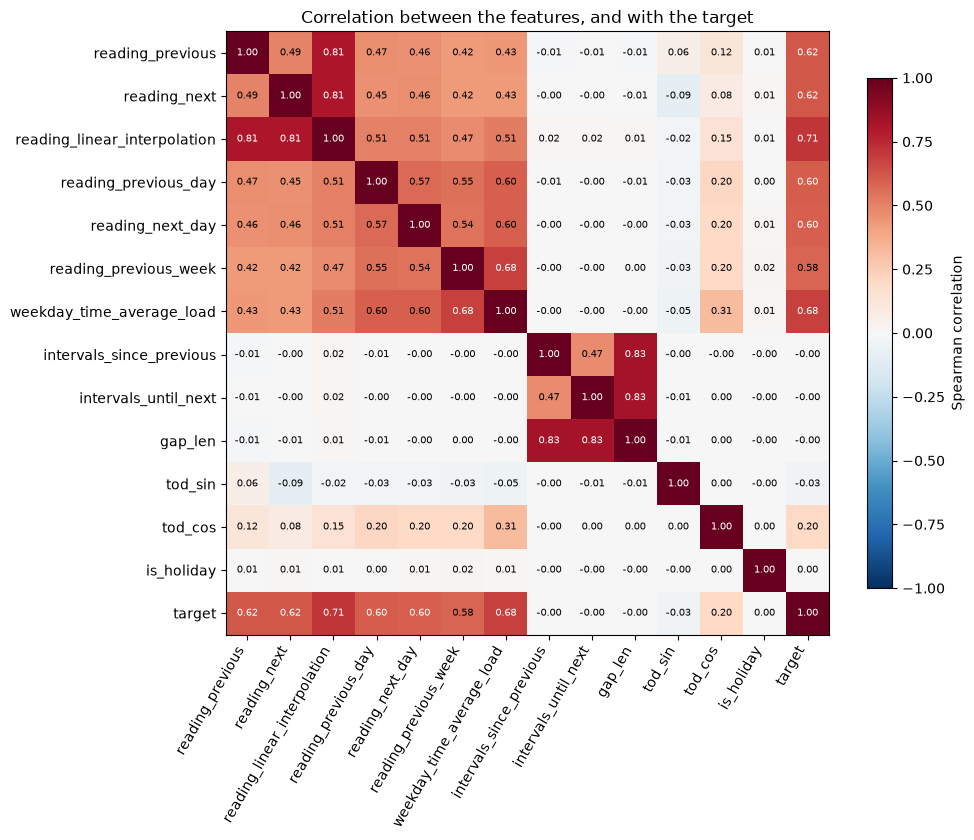

In [16]:
# Spearman correlation on a sample of the training rows; it works on ranks, so a few
# spikes don't dominate it. The last row is each feature against the hidden reading.
rng = np.random.default_rng(SEED)
sample = rng.choice(len(train_rows["y"]), size=min(200_000, len(train_rows["y"])), replace=False)
table = pd.DataFrame(train_rows["X"][sample], columns=FEATURES)
table["target"] = train_rows["y"][sample] / train_rows["mean_load"][sample]
corr = table.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
image = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.6 else "black")
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Correlation between the features, and with the target")
plt.tight_layout()

No two features are correlated above 0.9, so none of them repeats another and I
keep all 13.

## 7. Baselines

The model has to beat the simple methods a utility would otherwise use:

| Name | Method |
|---|---|
| `linear` | linear interpolation across the gap (the current practice) |
| `last_observed` | repeat the last reading before the gap (last observation carried forward) |
| `same_time_previous_day` | the same time on the nearest earlier day that reported |
| `weekday_time_average` | the meter's average for that weekday and time of day over the training period |

In [17]:
BASELINES = ["linear", "last_observed", "same_time_previous_day", "weekday_time_average"]

def same_time_previous_day(column, rows, max_days_back=14):
    out = np.full(rows.size, np.nan)
    pending = np.ones(rows.size, dtype=bool)
    for day in range(1, max_days_back + 1):
        source = rows - day * 96
        usable = pending & (source >= 0)
        candidate = np.full(rows.size, np.nan)
        candidate[usable] = column[source[usable]]
        found = usable & ~np.isnan(candidate)
        out[found] = candidate[found]
        pending &= ~found
    return out

def baseline_predictions(values, rows, weekday_time_average_load):
    # recomputed scenario by scenario, so each sees the same gaps the model saw
    slot = index.dayofweek.to_numpy() * 96 + index.hour.to_numpy() * 4 + index.minute.to_numpy() // 15
    out = {name: [] for name in BASELINES}
    for scenario in np.unique(rows["scenario"]):
        sel = rows["scenario"] == scenario
        mask = np.zeros(values.shape, dtype=bool)
        mask[rows["position"][sel], rows["meter"][sel]] = True
        masked = values.copy()
        masked[mask] = np.nan
        for j in range(values.shape[1]):
            r = np.flatnonzero(mask[:, j])
            if r.size == 0:
                continue
            prev_value, _, interp, *_ = neighbours(masked[:, j])
            previous_day = same_time_previous_day(masked[:, j], r)
            typical = weekday_time_average_load[j][slot[r]]
            out["linear"].append(interp[r])
            out["last_observed"].append(prev_value[r])
            out["same_time_previous_day"].append(np.where(np.isnan(previous_day), interp[r], previous_day))
            out["weekday_time_average"].append(np.where(np.isnan(typical), interp[r], typical))
    return {name: np.concatenate(parts) for name, parts in out.items()}

## 8. The model

The model is scikit-learn's `HistGradientBoostingRegressor`, a gradient-boosted
tree model. Each missing reading is one row of the feature table, and I chose
boosted trees over linear regression for three reasons:

- The right weighting depends on the gap. In a 15-minute gap the readings next to
  it are almost the answer; in a 24-hour gap yesterday and the meter's usual week
  matter more. Linear regression fits one set of weights for every row. Trees
  split on `gap_len` and `intervals_since_previous` and learn different rules
  for different gaps, so those interactions don't have to be written by hand.
- Load changes in steps through the day (people come home, air conditioners
  switch on), which a weighted sum of the calendar features cannot follow.
- There may be no reading yesterday or last week either. Trees take `NaN` as it
  is; linear regression needs it filled in first.

The ablation further down fits linear regression on the same features to measure
the difference.

### Target and loss

- The model predicts the correction to linear interpolation (the residual), and
  interpolation is added back. With nothing to correct, the model returns the
  linear interpolation.
- It is trained with absolute error, which matches the error being reported.

Early stopping holds out 10% of the training rows and stops when 25 rounds in a
row bring no improvement, up to 2,000 rounds. The ablation measures what the
target and the loss are worth.

In [18]:
def interpolation_level(X):
    level = X[:, FEATURES.index("reading_linear_interpolation")]
    level = np.where(np.isfinite(level), level, X[:, FEATURES.index("weekday_time_average_load")])
    return np.where(np.isfinite(level), level, 0.0)

def make_model(loss="absolute_error", max_iter=2000):
    return HistGradientBoostingRegressor(
        loss=loss, max_iter=max_iter, learning_rate=0.06, max_leaf_nodes=63,
        min_samples_leaf=40, l2_regularization=1.0, early_stopping=True,
        validation_fraction=0.1, n_iter_no_change=25, random_state=SEED)

def fit(rows, target="residual", loss="absolute_error", max_iter=2000):
    y = rows["y"] / rows["mean_load"]
    if target == "residual":
        y = y - interpolation_level(rows["X"])
    return make_model(loss, max_iter).fit(rows["X"], y)

def predict(model, X, mean_load_per_row, target="residual"):
    out = model.predict(X)
    if target == "residual":
        out = out + interpolation_level(X)
    return np.maximum(out * mean_load_per_row, 0.0)    # load cannot be negative

model = fit(train_rows)
print(f"fitted on {len(train_rows['y']):,} rows, {model.n_iter_} boosting rounds")

fitted on 908,108 rows, 2000 boosting rounds


validation loss: 0.561 before the first tree, 0.395 after 2,000


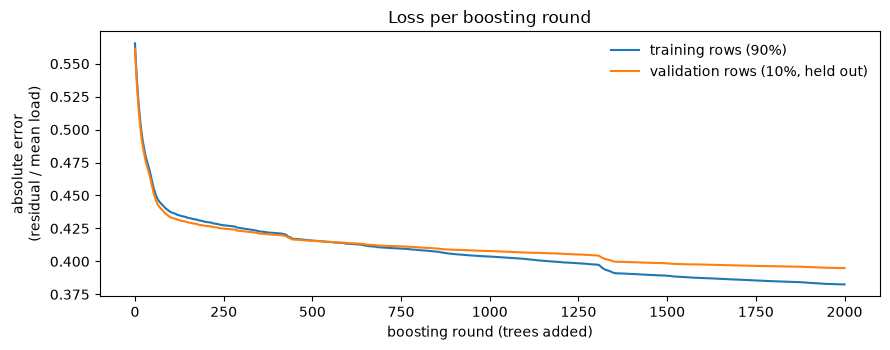

In [19]:
# loss after every boosting round, on the training rows and on the 10% held out for early stopping
# (scikit-learn stores minus the loss as the score, so the sign is flipped back)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(-model.train_score_, label="training rows (90%)")
ax.plot(-model.validation_score_, label="validation rows (10%, held out)")
ax.set_xlabel("boosting round (trees added)")
ax.set_ylabel("absolute error\n(residual / mean load)")
ax.set_title("Loss per boosting round")
ax.legend(frameon=False)
plt.tight_layout()
print(f"validation loss: {-model.validation_score_[0]:.3f} before the first tree, "
      f"{-model.validation_score_[-1]:.3f} after {model.n_iter_:,}")

Round 0 is the model before any tree is added, which is close to linear
interpolation. The validation loss falls quickly over the first hundred rounds
and then keeps falling slowly up to round 2,000, so early stopping never stops
the training and more rounds would still help a little. The two curves stay
close, so there is no sign of overfitting. By the end the training loss is a
little lower, because the trees are fitted to those rows.

## 9. Evaluation

Every method fills the same simulated gaps in the test period.

- nMAE is the mean absolute error divided by the meter's mean load, so meters of
  different sizes can be compared (a normalised MAE).
- MAE in kW is also reported, because it is not affected by meters whose mean is
  close to zero.
- Results are split by gap length. Interpolation is excellent across 15 minutes
  and poor across a day.
- The median across meters is used, because a few nearly empty meters would
  dominate a mean.

In [20]:
predictions = {"model": predict(model, test_rows["X"], test_rows["mean_load"])}
predictions.update(baseline_predictions(values, test_rows, weekday_time_average_load))
y, s = test_rows["y"], test_rows["mean_load"]

def metrics(y, p, s):
    big = y > 0.01 * s
    return {"MAE kW": np.nanmean(np.abs(p - y)), "nMAE": np.nanmean(np.abs(p - y) / s),
            "RMSE kW": np.sqrt(np.nanmean((p - y) ** 2)),
            "MAPE %": np.nanmean(np.abs(p - y)[big] / y[big]) * 100}

overall = pd.DataFrame({name: metrics(y, p, s) for name, p in predictions.items()}).T
overall.sort_values("nMAE").round(3)

,MAE kW,nMAE,RMSE kW,MAPE %
model,0.356,0.585,1.294,52.581
linear,0.527,0.691,1.928,86.265
weekday_time_average,0.529,0.778,1.484,132.649
last_observed,0.706,0.806,2.490,115.926
same_time_previous_day,0.739,0.927,2.475,135.321


In [21]:
LABELS = {1: "15 min", 4: "1 h", 12: "3 h", 20: "5 h", 32: "8 h", 48: "12 h", 64: "16 h", 96: "24 h"}
errors = pd.DataFrame({name: np.abs(p - y) / s for name, p in predictions.items()})
errors["meter"], errors["gap"] = test_rows["meter"], test_rows["gap_len"].astype(int)

# mean error per meter and gap length, then the median across meters
by_gap = (errors.groupby(["gap", "meter"]).mean().groupby("gap").median()
          .rename(index=LABELS)[["model", *BASELINES]])
by_gap.round(3)

,model,linear,last_observed,same_time_previous_day,weekday_time_average
gap,,,,,
15 min,0.154,0.157,0.204,0.623,0.490
1 h,0.203,0.217,0.320,0.595,0.489
3 h,0.280,0.305,0.443,0.561,0.488
5 h,0.290,0.355,0.501,0.547,0.485
8 h,0.309,0.458,0.548,0.536,0.439
12 h,0.324,0.484,0.593,0.542,0.439
16 h,0.327,0.541,0.600,0.538,0.447
24 h,0.408,0.610,0.601,0.554,0.470


median per-meter nMAE, all gaps: model 0.345, linear 0.426
the model is better than linear interpolation on 89% of meters


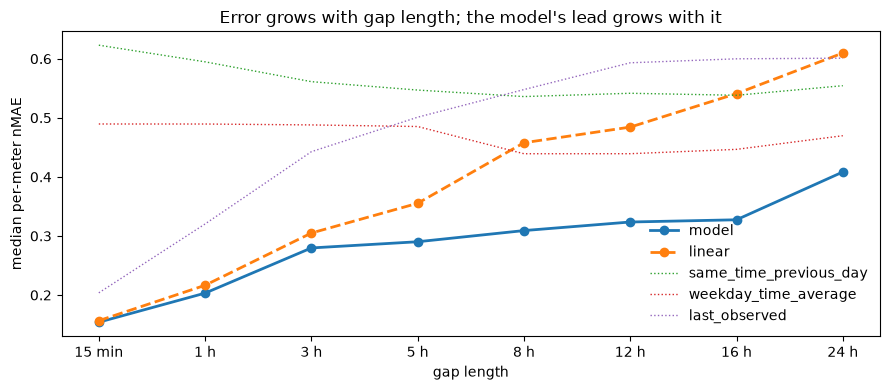

In [22]:
per_meter = errors.groupby("meter")[["model", "linear"]].mean()
better = (per_meter["model"] < per_meter["linear"]).mean()
print(f"median per-meter nMAE, all gaps: model {per_meter['model'].median():.3f}, "
      f"linear {per_meter['linear'].median():.3f}")
print(f"the model is better than linear interpolation on {better:.0%} of meters")

fig, ax = plt.subplots(figsize=(9, 4))
for name, style in [("model", "-o"), ("linear", "--o"), ("same_time_previous_day", ":"),
                    ("weekday_time_average", ":"), ("last_observed", ":")]:
    ax.plot(by_gap.index, by_gap[name], style, label=name, lw=2 if name in ("model", "linear") else 1)
ax.set_xlabel("gap length"); ax.set_ylabel("median per-meter nMAE")
ax.set_title("Error grows with gap length; the model's lead grows with it")
ax.legend(frameon=False)
plt.tight_layout()

Across 15 minutes the model and linear interpolation are level: the model
predicts a correction to interpolation and has little to correct. On longer gaps
linear interpolation cuts through a day that has a shape, and the model, which
knows the meter's daily pattern, pulls ahead.

Below are three gaps from the test period whose true readings were hidden. Each
method filled them, and the hidden readings are drawn back in.

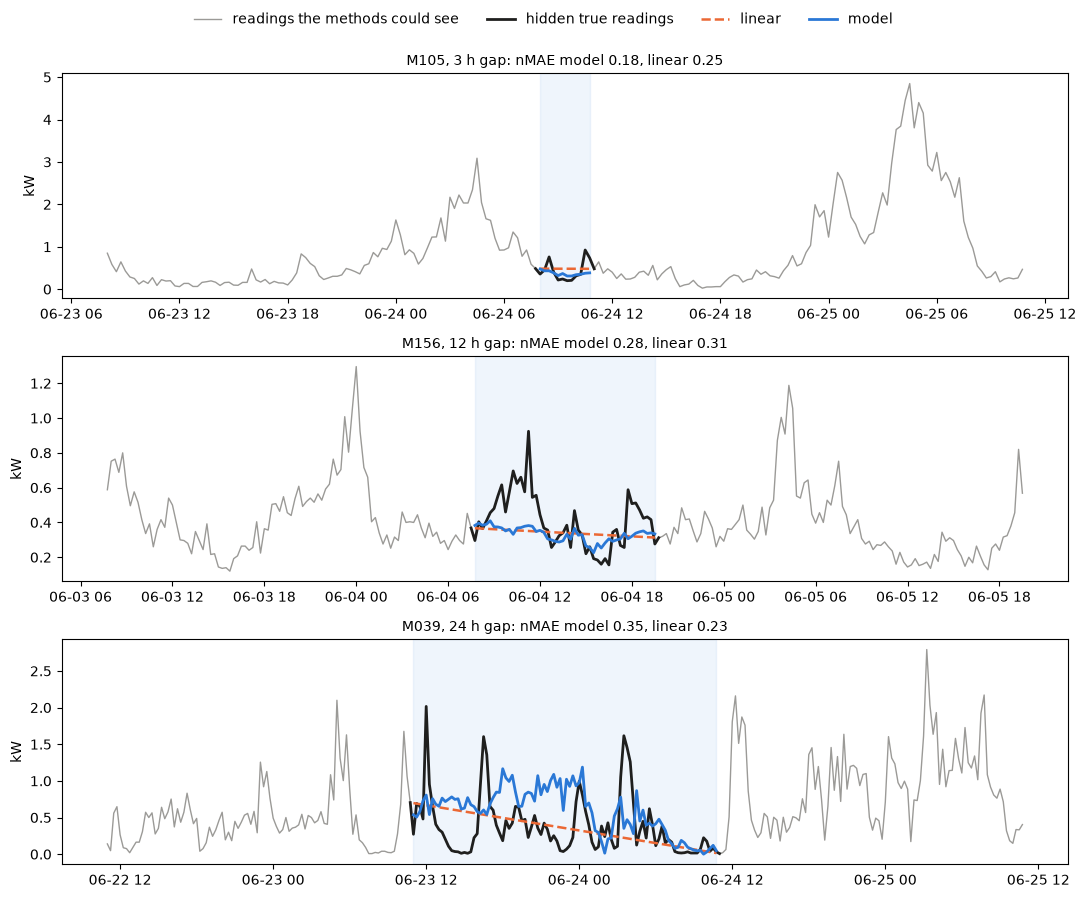

In [23]:
# number the simulated test gaps: a new gap starts where the meter, scenario or position jumps
jump = ((np.diff(test_rows["position"]) != 1) | (np.diff(test_rows["meter"]) != 0)
        | (np.diff(test_rows["scenario"]) != 0))
gap_id = np.r_[0, np.cumsum(jump)]
per_gap = pd.DataFrame({"gap": gap_id, "meter": test_rows["meter"], "length": test_rows["gap_len"].astype(int),
                        "model": errors["model"], "linear": errors["linear"]}).groupby("gap").agg(
    meter=("meter", "first"), length=("length", "first"), model=("model", "mean"), linear=("linear", "mean"))

fig, axes = plt.subplots(3, 1, figsize=(11, 9))
for ax, length in zip(axes, [12, 48, 96]):
    candidates = per_gap[(per_gap["length"] == length) & (mean_load[per_gap["meter"]] >= 0.2)]
    pick = (candidates["model"] - candidates["model"].median()).abs().idxmin()
    rows = np.flatnonzero(gap_id == pick)
    j, pos = test_rows["meter"][rows[0]], test_rows["position"][rows]
    around = np.arange(max(pos[0] - 96, 0), min(pos[-1] + 97, len(index)))
    outside = values[around, j].copy()
    outside[np.isin(around, pos)] = np.nan
    edge = np.arange(pos[0] - 1, pos[-1] + 2)          # the hidden readings plus one either side
    ax.axvspan(index[pos[0]], index[pos[-1]], color="#2a78d6", alpha=0.07)
    ax.plot(index[around], outside, color="#9b9a97", lw=1, label="readings the methods could see")
    ax.plot(index[edge], values[edge, j], color="#1f1f1e", lw=2, label="hidden true readings")
    ax.plot(index[pos], predictions["linear"][rows], "--", color="#eb6834", lw=1.8, label="linear")
    ax.plot(index[pos], predictions["model"][rows], color="#2a78d6", lw=2, label="model")
    ax.set_ylabel("kW")
    ax.set_title(f"{meters[j]}, {LABELS[length]} gap: nMAE model {per_gap.loc[pick, 'model']:.2f}, "
                 f"linear {per_gap.loc[pick, 'linear']:.2f}", fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.96))

## 10. Ablation

The same training rows and the same test gaps, changing one thing at a time
(median per-meter nMAE). The first three rows use a limit of 400 boosting rounds.
The fourth row uses linear regression on the same features instead of trees.

In [24]:
variants = [("level", "squared_error", 400), ("level", "absolute_error", 400),
            ("residual", "absolute_error", 400)]
ablation = {}
for target, loss, max_iter in variants:
    print(f"training trees: {target} target, {loss}, up to {max_iter} rounds ...", end=" ", flush=True)
    m = fit(train_rows, target, loss, max_iter)
    print(f"done ({m.n_iter_} rounds)")
    ablation[f"{target} + {loss}, {max_iter} rounds"] = np.abs(
        predict(m, test_rows["X"], s, target) - y) / s
# linear regression on the same rows, target and loss (absolute error, fitted by stochastic
# gradient descent); NaN features are filled with the median and flagged
linreg = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                       SGDRegressor(loss="epsilon_insensitive", epsilon=0.0, alpha=1e-6,
                                    max_iter=20, tol=None, random_state=SEED))
print("training linear regression: residual target, absolute error ...", end=" ", flush=True)
linreg.fit(train_rows["X"], train_rows["y"] / train_rows["mean_load"] - interpolation_level(train_rows["X"]))
print("done")
ablation["linear regression, residual + absolute_error"] = np.abs(predict(linreg, test_rows["X"], s) - y) / s
ablation["residual + absolute_error, 2000 rounds (final)"] = errors["model"].to_numpy()
ablation["linear interpolation"] = errors["linear"].to_numpy()

table = {}
for name, e in ablation.items():
    frame = pd.DataFrame({"e": e, "meter": test_rows["meter"], "gap": test_rows["gap_len"].astype(int)})
    per_gap = frame.groupby(["gap", "meter"])["e"].mean().groupby("gap").median()
    table[name] = {"15 min": per_gap[1], "5 h": per_gap[20], "24 h": per_gap[96],
                   "all gaps": frame.groupby("meter")["e"].mean().median()}
pd.DataFrame(table).T.round(3)

training trees: level target, squared_error, up to 400 rounds ... done (60 rounds)
training trees: level target, absolute_error, up to 400 rounds ... done (400 rounds)
training trees: residual target, absolute_error, up to 400 rounds ... done (400 rounds)
training linear regression: residual target, absolute error ... done


,15 min,5 h,24 h,all gaps
"level + squared_error, 400 rounds",0.207,0.344,0.433,0.388
"level + absolute_error, 400 rounds",0.165,0.294,0.383,0.336
"residual + absolute_error, 400 rounds",0.157,0.289,0.411,0.334
"linear regression, residual + absolute_error",0.299,0.348,0.424,0.402
"residual + absolute_error, 2000 rounds (final)",0.154,0.290,0.408,0.345
linear interpolation,0.157,0.355,0.610,0.426


With squared error the model loses to linear interpolation on 15-minute gaps
(0.207 against 0.157). Absolute error and the residual target bring it level (0.157).
Linear regression on the same features does worse than the trees at every gap
length and loses badly at 15 minutes (0.299).

## 11. Using the model on real meter gaps

Each meter's mean load and weekday time average load come from that meter's own
readings, so the model can fill one meter on its own, as it would for a single
customer's request.

- Gaps of up to 24 hours are filled.
- Longer gaps are marked `needs_review` and left empty. A multi-day gap filled
  from a "typical day" would look like real data without being real.
- Every value keeps its source, and filled values carry an error band from the
  backtest (the model's median nMAE for that gap length).

In [25]:
confidence = {g: by_gap.loc[LABELS[g], "model"] for g in GAP_LENGTHS}

def fill(values, model):
    mean_load_all = compute_mean_load(values)
    weekday_time_average_load_all = compute_weekday_time_average_load(values, index)
    missing = np.isnan(values)
    X, meter, position = build_features(values, missing, mean_load_all, weekday_time_average_load_all, holiday)
    gap_len = X[:, FEATURES.index("gap_len")]
    fillable = gap_len <= MAX_FILL
    filled = values.copy()
    filled[position[fillable], meter[fillable]] = predict(
        model, X[fillable], mean_load_all[meter[fillable]])
    source = np.where(missing, "needs_review", "observed").astype(object)
    source[position[fillable], meter[fillable]] = "imputed"
    nearest = np.array(GAP_LENGTHS)[np.abs(gap_len[:, None] - np.array(GAP_LENGTHS)).argmin(1)]
    band = np.full(values.shape, np.nan)
    band[position, meter] = [confidence[g] for g in nearest] * mean_load_all[meter]
    return filled, source, band

filled, source, band = fill(values, model)
counts = pd.Series(source.ravel()).value_counts()
counts.to_frame("readings")

,readings
observed,3131214
needs_review,337203
imputed,6783


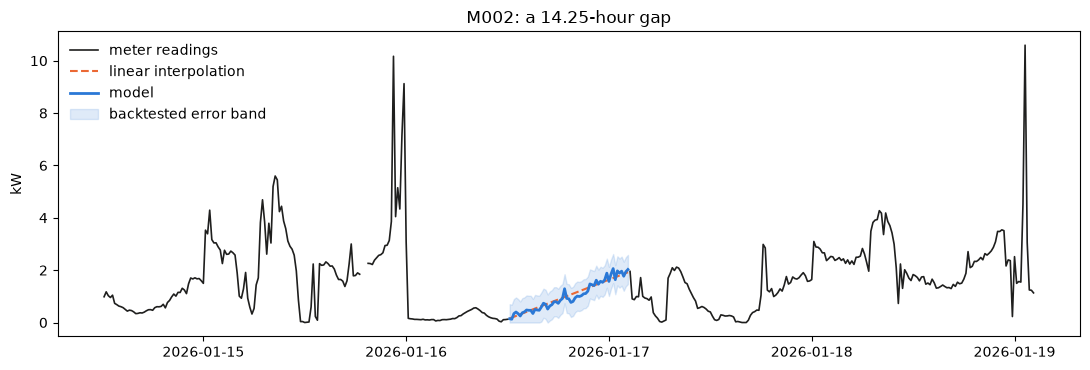

In [26]:
# The first meter with a gap of 12 to 24 hours, filled, with linear interpolation for comparison.
# Nothing was recorded inside a real gap, so the meter line stops there.
j = next(j for j in range(len(meters))
         if any(48 <= n <= 96 for _, n in gap_runs(values[:, j])))
start, n = next((a, n) for a, n in gap_runs(values[:, j]) if 48 <= n <= 96)
view = slice(start - 2 * 96, start + n + 2 * 96)
inside = np.arange(start, start + n)
line = pd.Series(values[:, j]).interpolate(limit_area="inside").to_numpy()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(index[view], values[view, j], color="#1f1f1e", lw=1.2, label="meter readings", zorder=3)
ax.plot(index[inside], line[inside], "--", color="#eb6834", lw=1.5, label="linear interpolation")
ax.plot(index[inside], filled[inside, j], color="#2a78d6", lw=2, label="model")
ax.fill_between(index[inside], np.maximum(filled[inside, j] - band[inside, j], 0),
                filled[inside, j] + band[inside, j], color="#2a78d6", alpha=0.15,
                label="backtested error band")
ax.set_ylabel("kW"); ax.set_title(f"{meters[j]}: a {n / 4:g}-hour gap")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

## 12. Saving the model

In [27]:
joblib.dump({"model": model, "features": FEATURES, "target": "residual",
             "max_fill_intervals": MAX_FILL, "confidence_nmae": confidence},
            "smart_meter_data_imputation_model.joblib")
print("saved smart_meter_data_imputation_model.joblib")

saved smart_meter_data_imputation_model.joblib
